## FFT of $f(x) = \dfrac{1}{a^2x^4 + b^2}$

**The question:** Starting from the FFT code in `scipy_fft.ipynb` (section *Fourier Transform of the Single Square Wave Function*):

1. Compute the FFT $F(k)$ of $f(x) = 1/(a^2x^4+b^2)$ for $a = b = 2$, and plot its **real part**, **imaginary part** and **absolute value**.
2. Change $a$ to $1$ (keep $b=2$). Describe and plot how $F(k)$ changes.
3. Keep $a = 1$, but replace $x$ with $x-2$ (shift the function 2 units to the right). Describe and plot how $F(k)$ changes.
4. Plot the three versions of $F(k)$ **one below the other**, so the differences are easy to see.

In `scipy_fft.ipynb` the square-wave example changes the *width* of a pulse and shows that its spectrum gets narrower or wider (the scaling theorem).
Here, case 2 is the same kind of experiment (changing $a$ changes the width of $f$), and case 3 shows a second theorem (shifting $f$ changes only the *phase* of $F$).

### Setup
We use the same tools as `scipy_fft.ipynb`: `numpy`, `matplotlib` and `scipy.fft.fft` / `fftfreq`.

In [1]:
import numpy as np
from matplotlib import pyplot as plt
from scipy.fft import fft, fftfreq, fftshift, ifftshift

### Sampling the function

In the square-wave example the signal was sampled on `np.linspace(0, DURATION, N, endpoint=False)`, with the pulse placed in the middle of the interval.
Here we do the same thing, but we label the grid so that its middle point is $x=0$, i.e. $x \in [-L/2, L/2)$.

* $f(x)$ decays like $1/x^4$, so a window of length $L = 200$ is more than enough. At the edges $f \approx 10^{-8}$, which is effectively zero.
* With $N = 2^{14}$ samples the step is $dx = L/N \approx 0.012$, which resolves the bump (width $\approx 1$) very well.

In [2]:
N  = 2**14          # number of samples (like SAMPLE_RATE * DURATION)
L  = 200.0          # length of the x window (like DURATION)
dx = L / N          # sample spacing (like 1 / SAMPLE_RATE)

x = np.linspace(-L/2, L/2, N, endpoint=False)   # x[N//2] == 0

def f(x, a, b, shift=0.0):
    # f(x) = 1 / (a^2 (x - shift)^4 + b^2)
    return 1.0 / (a**2 * (x - shift)**4 + b**2)

### Computing $F(k)$ with the FFT

We want the continuous Fourier transform
$$F(k) = \int_{-\infty}^{\infty} f(x)\, e^{-ikx}\, dx ,$$
and the FFT gives a discrete sum $\sum_n f_n e^{-2\pi i m n / N}$. Three small steps turn one into the other:

1. **`ifftshift(y)` before `fft`**: `fft` assumes the *first* sample is at $x=0$. Our $x=0$ is in the middle of the array, so we rotate the array to put it first. Without this step every value of $F$ picks up an extra factor $(-1)^m$, so the real and imaginary parts flip sign at every point. The magnitude is unaffected, which is why `scipy_fft.ipynb` only had to plot `np.abs(yf)`. Here we also need the real and imaginary parts, so the step matters.
2. **Multiply by `dx`**: this turns the sum into an approximation of the integral. Then $F(0)$ equals the area under $f$.
3. **`k = 2π · fftfreq(N, dx)`**: `fftfreq` returns frequency in cycles per unit of $x$ (Hz in the audio example). Multiplying by $2\pi$ gives the angular wavenumber $k$. `fftshift` orders the output from negative to positive $k$ for plotting.

In [3]:
def fourier_transform(y):
    F = fftshift(fft(ifftshift(y))) * dx
    k = 2*np.pi * fftshift(fftfreq(N, dx))
    return k, F

### Exact answer, for checking

This transform can be done analytically (contour integration). With $c = \sqrt{b/a}$:
$$F(k) = \frac{\pi}{\sqrt2\, a^2 c^3}\; e^{-|k|c/\sqrt2}\Big[\cos\!\big(\tfrac{|k|c}{\sqrt2}\big) + \sin\!\big(\tfrac{|k|c}{\sqrt2}\big)\Big]$$

It is a decaying exponential multiplied by an oscillation, so $F(k)$ is real and even, and it dips slightly *below zero*.
A shift $x \to x - x_0$ multiplies it by $e^{-ikx_0}$ (shift theorem).

In [4]:
def F_exact(k, a, b, shift=0.0):
    c = np.sqrt(b / a)
    q = np.abs(k) * c / np.sqrt(2)
    F0 = np.pi / (np.sqrt(2) * a**2 * c**3)
    return F0 * np.exp(-q) * (np.cos(q) + np.sin(q)) * np.exp(-1j * k * shift)

### Case 1: $a = b = 2$

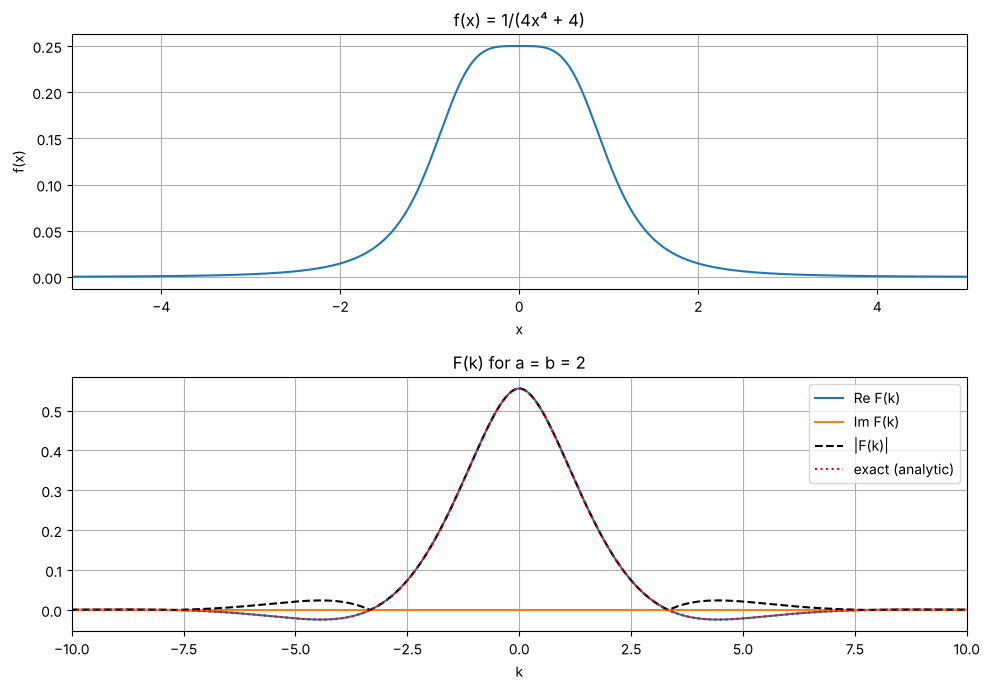

F(0) from FFT     : 0.5553602006031274
F(0) exact π/(4√2): 0.5553603672697958
max |Im F|        : 8.097634975751111e-17
max |FFT - exact| : 1.6666666835529753e-07


In [5]:
a, b = 2, 2
y1 = f(x, a, b)
k, F1 = fourier_transform(y1)

fig, (ax0, ax1) = plt.subplots(2, 1, figsize=(10, 7))
ax0.plot(x, y1)
ax0.set_xlim(-5, 5); ax0.set_xlabel('x'); ax0.set_ylabel('f(x)')
ax0.set_title('f(x) = 1/(4x⁴ + 4)'); ax0.grid()

ax1.plot(k, F1.real, label='Re F(k)')
ax1.plot(k, F1.imag, label='Im F(k)')
ax1.plot(k, np.abs(F1), 'k--', label='|F(k)|')
ax1.plot(k, F_exact(k, a, b).real, ':', color='red', label='exact (analytic)')
ax1.set_xlim(-10, 10); ax1.set_xlabel('k'); ax1.set_title('F(k) for a = b = 2')
ax1.legend(); ax1.grid()
plt.tight_layout(); plt.show()

print('F(0) from FFT     :', F1.real[N//2])
print('F(0) exact π/(4√2):', np.pi / (4*np.sqrt(2)))
print('max |Im F|        :', np.abs(F1.imag).max())
print('max |FFT - exact| :', np.abs(F1 - F_exact(k, a, b)).max())

**Observations, case 1:**
* $f$ is real and even, so $F(k)$ is **real and even**. The imaginary part is zero (about $10^{-17}$, rounding error).
* Because $F$ is real, $|F(k)|$ equals $\mathrm{Re}\,F(k)$ wherever $F>0$. Where $F$ dips below zero (around $|k| > 3.3$), $|F|$ is its mirror image above the axis.
* The FFT result lies on top of the exact formula.

### Case 2: $a = 1$, $b = 2$

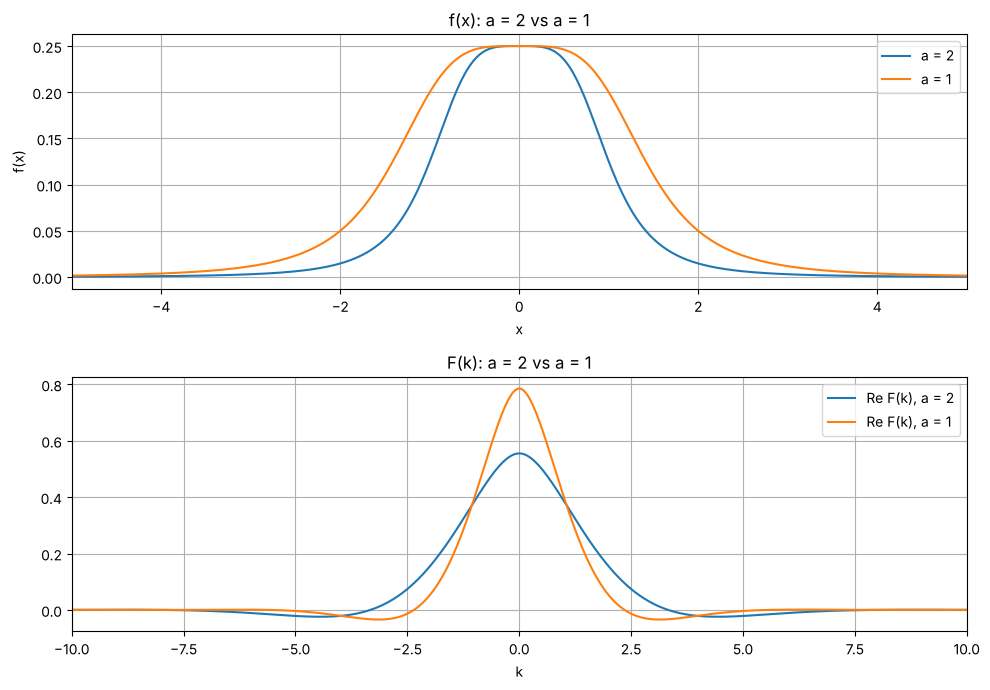

F(0), a=2: 0.5553602006031274    F(0), a=1: 0.7853974967307831   (exact π/4 = 0.7853981633974483 )
max |Im F|: 9.283481101907132e-17


In [6]:
y2 = f(x, 1, 2)
_, F2 = fourier_transform(y2)

fig, (ax0, ax1) = plt.subplots(2, 1, figsize=(10, 7))
ax0.plot(x, y1, label='a = 2'); ax0.plot(x, y2, label='a = 1')
ax0.set_xlim(-5, 5); ax0.set_xlabel('x'); ax0.set_ylabel('f(x)')
ax0.set_title('f(x): a = 2 vs a = 1'); ax0.legend(); ax0.grid()

ax1.plot(k, F1.real, label='Re F(k), a = 2')
ax1.plot(k, F2.real, label='Re F(k), a = 1')
ax1.set_xlim(-10, 10); ax1.set_xlabel('k'); ax1.set_title('F(k): a = 2 vs a = 1')
ax1.legend(); ax1.grid()
plt.tight_layout(); plt.show()

print('F(0), a=2:', F1.real[N//2], '   F(0), a=1:', F2.real[N//2], '  (exact π/4 =', np.pi/4, ')')
print('max |Im F|:', np.abs(F2.imag).max())

**Observations, case 2:**
* With $a=1$, the $x^4$ term is 4 times weaker, so $f(x) = 1/(x^4+4)$ stays near its peak value $1/b^2 = 1/4$ for longer: the bump is **wider** in $x$ (its width scales like $\sqrt{b/a}$, which grows by $\sqrt2$).
* $F(k)$ becomes **narrower** in $k$ by the same factor $\sqrt2$: it decays faster and crosses zero sooner ($k \approx 2.36$ instead of $3.33$).
  This is the same scaling theorem as in the square-wave example: *stretch in $x$, compress in $k$*.
* $F(0)$ equals the area under $f$, so it **grows** from $0.555$ to $\pi/4 \approx 0.785$.
* $f$ is still even, so $F$ is still **real** ($\mathrm{Im}\,F = 0$).

### Case 3: $a = 1$, $b = 2$, $x \to x - 2$

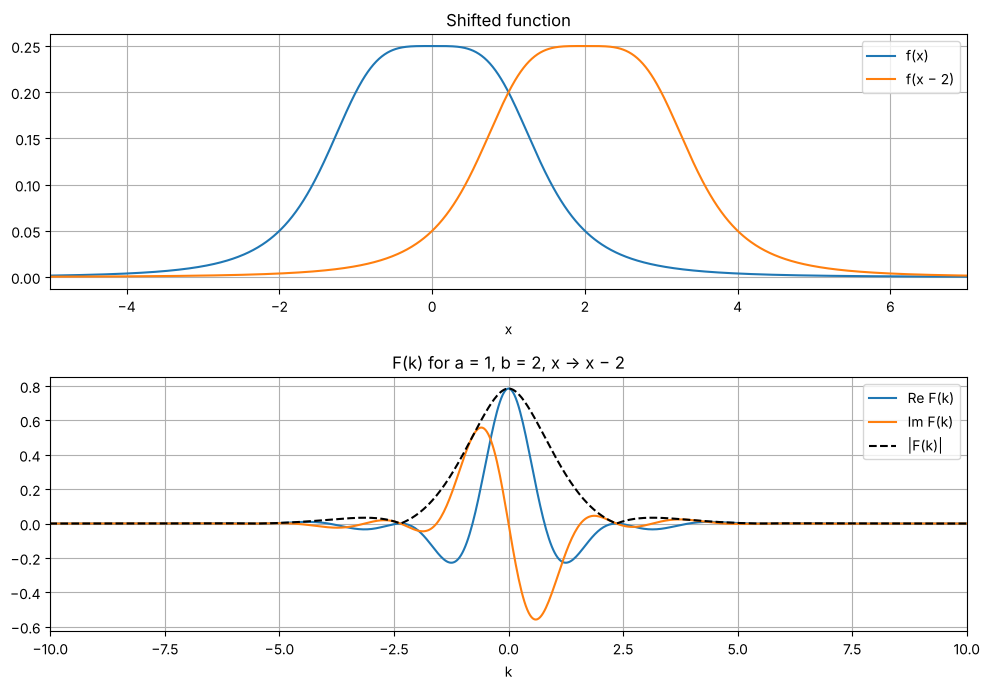

max | |F3| - |F2| | : 1.6113863576805443e-09
max |F3 - e^{-2ik} F2|: 1.6113863576805443e-09


In [7]:
y3 = f(x, 1, 2, shift=2)
_, F3 = fourier_transform(y3)

fig, (ax0, ax1) = plt.subplots(2, 1, figsize=(10, 7))
ax0.plot(x, y2, label='f(x)'); ax0.plot(x, y3, label='f(x − 2)')
ax0.set_xlim(-5, 7); ax0.set_xlabel('x'); ax0.set_title('Shifted function'); ax0.legend(); ax0.grid()

ax1.plot(k, F3.real, label='Re F(k)')
ax1.plot(k, F3.imag, label='Im F(k)')
ax1.plot(k, np.abs(F3), 'k--', label='|F(k)|')
ax1.set_xlim(-10, 10); ax1.set_xlabel('k'); ax1.set_title('F(k) for a = 1, b = 2, x → x − 2')
ax1.legend(); ax1.grid()
plt.tight_layout(); plt.show()

print('max | |F3| - |F2| | :', np.abs(np.abs(F3) - np.abs(F2)).max())
print('max |F3 - e^{-2ik} F2|:', np.abs(F3 - np.exp(-2j*k) * F2).max())

**Observations, case 3:**
* Shift theorem: $f(x-2) \;\longleftrightarrow\; e^{-2ik}\,F(k)$, so
  $\mathrm{Re}\,F = F_2(k)\cos 2k$, $\mathrm{Im}\,F = -F_2(k)\sin 2k$.
* The **magnitude $|F(k)|$ is exactly the same as in case 2** (the difference printed above is at rounding-error level). A shift changes only the phase.
* The shifted function is no longer symmetric about $x=0$, so the **imaginary part is no longer zero**. Real and imaginary parts now oscillate with period $\pi$ in $k$, inside the envelope $\pm|F(k)|$.
* The real part stays even in $k$ and the imaginary part is odd, as it must be for any real $f$.

### The three versions of $F(k)$, one below the other
All three panels share the same axes, so differences in height, width and phase show up directly.

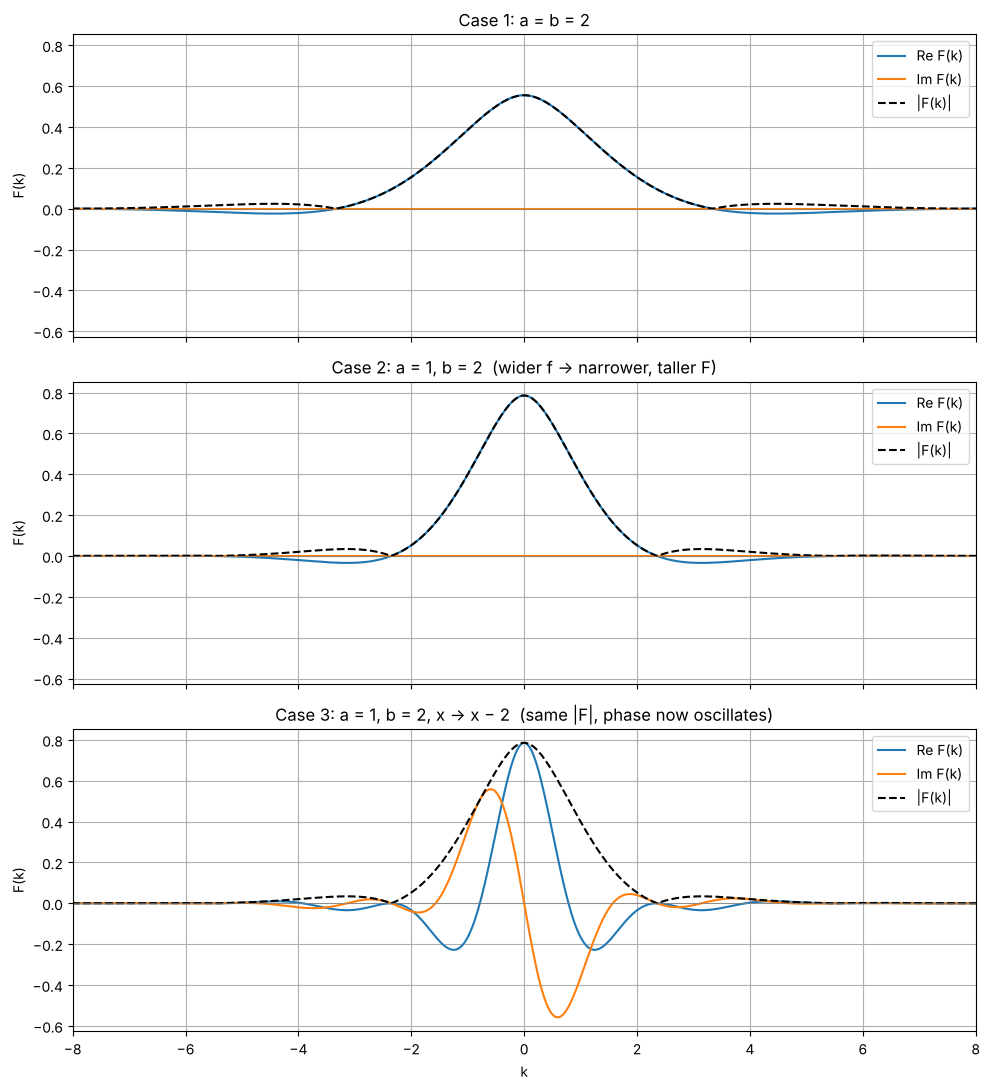

In [8]:
cases = [(F1, 'Case 1: a = b = 2'),
         (F2, 'Case 2: a = 1, b = 2  (wider f → narrower, taller F)'),
         (F3, 'Case 3: a = 1, b = 2, x → x − 2  (same |F|, phase now oscillates)')]

fig, axes = plt.subplots(3, 1, figsize=(10, 11), sharex=True, sharey=True)
for ax, (F, title) in zip(axes, cases):
    ax.plot(k, F.real, label='Re F(k)')
    ax.plot(k, F.imag, label='Im F(k)')
    ax.plot(k, np.abs(F), 'k--', label='|F(k)|')
    ax.axhline(0, color='gray', lw=0.5)
    ax.set_title(title); ax.set_ylabel('F(k)'); ax.grid(); ax.legend(loc='upper right')
axes[-1].set_xlim(-8, 8); axes[-1].set_xlabel('k')
plt.tight_layout()
plt.savefig('fft_three_cases.png', dpi=120)
plt.show()

### Summary

| | $f(x)$ | $F(k)$ |
|---|---|---|
| $a=b=2$ | even bump, width $\approx 1$ | real, even; $F(0) = \pi/(4\sqrt2) \approx 0.555$; decaying oscillation, first zero at $k\approx3.3$ |
| $a: 2 \to 1$ | bump **wider** by $\sqrt2$ | **narrower** by $\sqrt2$ and taller ($F(0)=\pi/4\approx0.785$); still real |
| $x \to x-2$ | same bump moved right by 2 | $|F|$ **unchanged**; phase factor $e^{-2ik}$ makes Re and Im oscillate; Im $\neq 0$ |

**Why this matters for speech:** spectrograms and MFCCs use the magnitude $|F|$ of each frame. Case 3 shows that $|F|$ does not depend on exactly where a sound sits in time, and case 2 shows the time–frequency trade-off that governs the choice of window length.